# Notebook 3: Eksperimen Fitur Dinamis — 2D CNN dengan SDCC

Eksperimen kedua menguji fitur SDCC (Shifted Delta Cepstral Coefficients) sebagai alternatif dari MFCC.

Berbeda dengan MFCC yang hanya menangkap karakteristik spektral pada satu frame, SDCC menghitung selisih (delta) antar-frame yang berjauhan sehingga diharapkan bisa menangkap perubahan dinamika nada antar waktu. Arsitektur CNN yang digunakan dibuat sebanding dengan Notebook 2 agar perbandingannya adil (apple-to-apple).

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

# 1. Kunci Random Seed agar eksperimen 100% Reproducible
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Cari otomatis file maqam_2d_dataset.npz di /kaggle/input (Output dari Notebook 1)
DATASET_PATH = None
for root, _, files in os.walk("/kaggle/input"):
    if "maqam_2d_dataset.npz" in files:
        DATASET_PATH = os.path.join(root, "maqam_2d_dataset.npz")
        break

if DATASET_PATH is None:
    raise FileNotFoundError("File maqam_2d_dataset.npz tidak ditemukan! Pastikan Notebook 1 sudah ditambahkan via '+ Add Input'.")

print(f"[INFO] Memuat dataset fitur dari: {DATASET_PATH}")
data = np.load(DATASET_PATH, allow_pickle=True)

# Muat fitur SDCC dan tambahkan dimensi channel: (Height=130, Width=91, Channel=1)
X_train = data['X_train_sdcc'][..., np.newaxis]
y_train = data['y_train']

X_val   = data['X_val_sdcc'][..., np.newaxis]
y_val   = data['y_val']

X_test  = data['X_test_sdcc'][..., np.newaxis]
y_test  = data['y_test']

CLASS_NAMES = [str(c) for c in data['class_names']]
NUM_CLASSES = len(CLASS_NAMES)

print(f"[INFO] Kelas Maqam ({NUM_CLASSES}) : {CLASS_NAMES}")
print(f"[INFO] X_train (SDCC) shape : {X_train.shape} | y_train shape: {y_train.shape}")
print(f"[INFO] X_val (SDCC) shape   : {X_val.shape}   | y_val shape  : {y_val.shape}")
print(f"[INFO] X_test (SDCC) shape  : {X_test.shape}  | y_test shape : {y_test.shape}")


[INFO] Memuat dataset fitur dari: /kaggle/input/notebooks/ahmadfikr/01-preprocessing-extraction/maqam_2d_dataset.npz
[INFO] Kelas Maqam (8) : ['Ajam', 'Bayati', 'Hijaz', 'Kurdi', 'Nahawand', 'Rast', 'Saba', 'Sikah']
[INFO] X_train (SDCC) shape : (6158, 130, 91, 1) | y_train shape: (6158,)
[INFO] X_val (SDCC) shape   : (385, 130, 91, 1)   | y_val shape  : (385,)
[INFO] X_test (SDCC) shape  : (385, 130, 91, 1)  | y_test shape : (385,)


### 2. Membangun Arsitektur 2D CNN untuk Fitur Dinamis SDCC


In [2]:
def build_cnn_2d_sdcc(input_shape, num_classes=8, l2_reg=1e-4, name="CNN_2D_SDCC"):
    l2 = regularizers.l2(l2_reg)
    inputs = layers.Input(shape=input_shape, name="input_sdcc")
    
    # Blok Konvolusi 1
    x = layers.Conv2D(32, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv1")(inputs)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.Activation('relu', name="relu1")(x)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)
    x = layers.SpatialDropout2D(0.20, name="spatial_drop1")(x)
    
    # Blok Konvolusi 2
    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv2")(x)
    x = layers.BatchNormalization(name="bn2")(x)
    x = layers.Activation('relu', name="relu2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool2")(x)
    x = layers.SpatialDropout2D(0.25, name="spatial_drop2")(x)
    
    # Blok Konvolusi 3
    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv3")(x)
    x = layers.BatchNormalization(name="bn3")(x)
    x = layers.Activation('relu', name="relu3")(x)
    x = layers.MaxPooling2D((2, 2), name="pool3")(x)
    x = layers.SpatialDropout2D(0.30, name="spatial_drop3")(x)
    
    # Global Average Pooling & Dense Classifier Head
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, use_bias=False, kernel_regularizer=l2, name="dense1")(x)
    x = layers.BatchNormalization(name="bn_dense")(x)
    x = layers.Activation('relu', name="relu_dense")(x)
    x = layers.Dropout(0.40, name="dropout_dense")(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="output_maqam")(x)
    
    model = models.Model(inputs=inputs, outputs=outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_cnn_2d_sdcc(input_shape=X_train.shape[1:], num_classes=NUM_CLASSES)
model.summary()


Model: "CNN_2D_SDCC"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_sdcc (InputLayer)         │ (None, 130, 91, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 130, 91, 32)    │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 130, 91, 32)    │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 130, 91, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 65, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop1                   │ (None, 65, 45, 32)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 65, 45, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 65, 45, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 65, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop2                   │ (None, 32, 22, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 22, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 22, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop3                   │ (None, 16, 11, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_dense (BatchNormalization)   │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_dense (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_maqam (Dense)            │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,272 (434.66 KB)

 Trainable params: 110,568 (431.91 KB)

 Non-trainable params: 704 (2.75 KB)

### 3. Pelatihan Model dengan Regularisasi dan Callbacks Adaptif
Menggunakan parameter dan callbacks yang konsisten dengan Eksperimen 1 untuk memastikan validitas perbandingan metodologis.


In [3]:
BEST_MODEL_PATH = "/kaggle/working/model_exp2_sdcc.keras"

cb_list = [
    callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS = 80
BATCH_SIZE = 32

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=cb_list,
    verbose=1
)


Epoch 1/80
191/193 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1398 - loss: 2.5219

E0000 00:00:1794887960.954472      70 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.1399 - loss: 2.5207
Epoch 1: val_loss improved from None to 2.08947, saving model to /kaggle/working/model_exp2_sdcc.keras

Epoch 1: finished saving model to /kaggle/working/model_exp2_sdcc.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 29s 74ms/step - accuracy: 0.1483 - loss: 2.4073 - val_accuracy: 0.1792 - val_loss: 2.0895 - learning_rate: 0.0010
Epoch 2/80
193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1588 - loss: 2.2699
Epoch 2: val_loss did not improve from 2.08947
193/193 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.1596 - loss: 2.2425 - val_accuracy: 0.1506 - val_loss: 2.0909 - learning_rate: 0.0010
Epoch 3/80
193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1564 - loss: 2.1881
Epoch 3: val_loss improved from 2.08947 to 2.07110, saving model to /kaggle/working/model_exp2_sdcc.keras

Epoch 3: finished saving model to /kaggle/working/model_exp2_sdcc.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.1609 - 

### 4. Visualisasi Kurva Loss & Accuracy (SDCC)


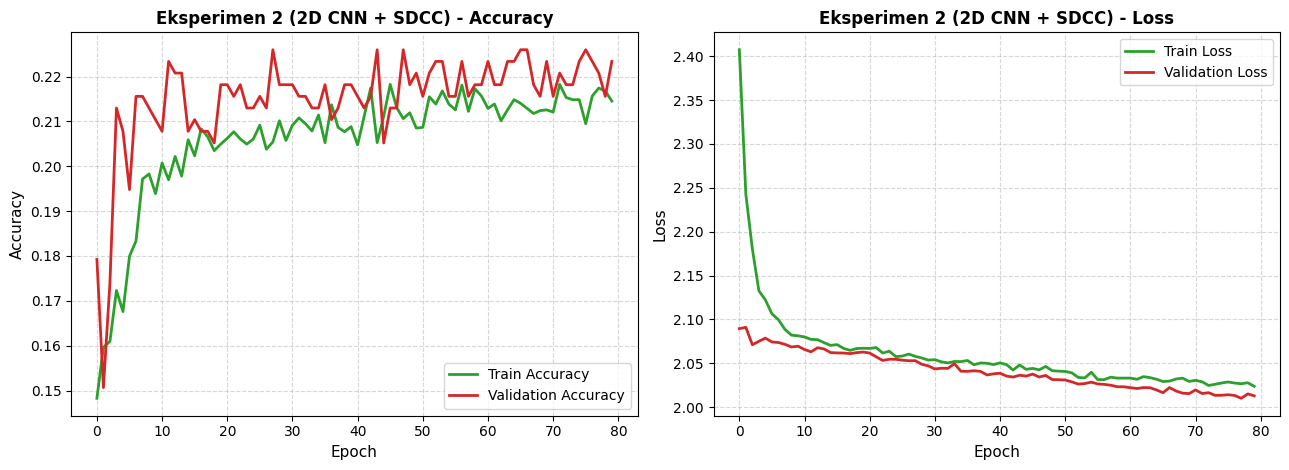

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Plot Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='#2ca02c', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='#d62728', linewidth=2)
axes[0].set_title('Eksperimen 2 (2D CNN + SDCC) - Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Accuracy', fontsize=11)
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Plot Loss
axes[1].plot(history.history['loss'], label='Train Loss', color='#2ca02c', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='#d62728', linewidth=2)
axes[1].set_title('Eksperimen 2 (2D CNN + SDCC) - Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Loss', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("/kaggle/working/kurva_training_exp2_sdcc.png", dpi=300)
plt.show()


### 5. Evaluasi Komprehensif pada Test Set (Fitur SDCC)


HASIL EVALUASI EKSPERIMEN 2: 2D CNN + SDCC (TEST SET)
Test Accuracy         : 21.82%
Macro Precision       : 8.66%
Macro Recall          : 14.38%
Macro F1-Score        : 8.56%
Weighted F1-Score     : 11.61%

Classification Report per Kelas Maqam:

              precision    recall  f1-score   support

        Ajam     0.0000    0.0000    0.0000        52
      Bayati     0.0000    0.0000    0.0000        35
       Hijaz     0.2035    0.8625    0.3294        80
       Kurdi     0.0000    0.0000    0.0000        34
    Nahawand     0.1000    0.0286    0.0444        35
        Rast     0.3889    0.2593    0.3111        54
        Saba     0.0000    0.0000    0.0000        52
       Sikah     0.0000    0.0000    0.0000        43

    accuracy                         0.2182       385
   macro avg     0.0866    0.1438    0.0856       385
weighted avg     0.1059    0.2182    0.1161       385



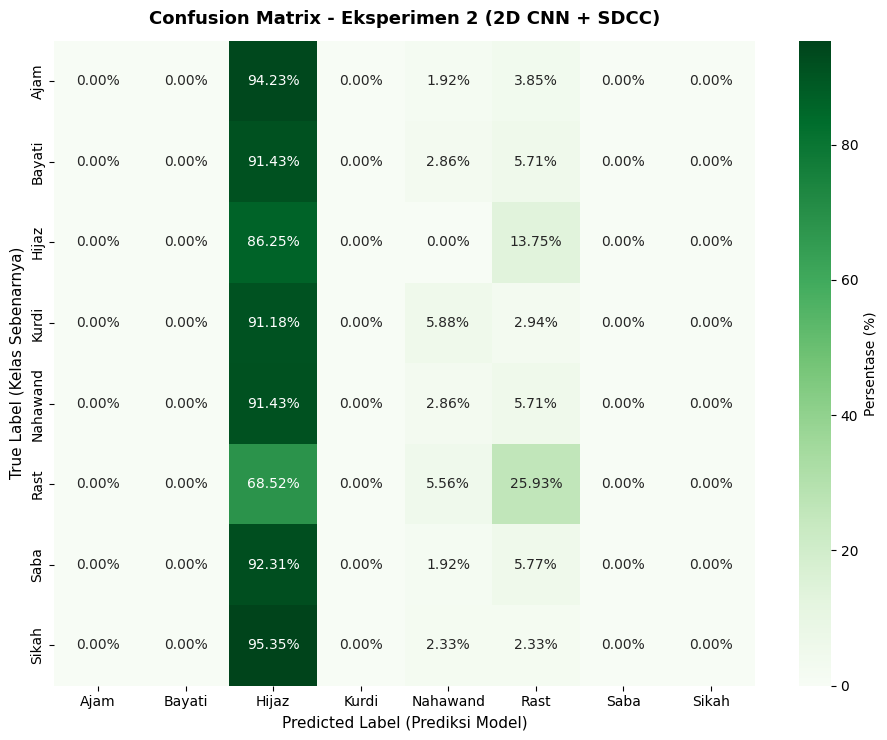

[SUKSES] Hasil evaluasi & model terbaik Eksperimen 2 berhasil disimpan.


In [5]:
# Muat bobot model terbaik
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

# Prediksi label pada Test Set
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Hitung metrik evaluasi
test_acc = accuracy_score(y_test, y_pred)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)

print("=" * 70)
print("HASIL EVALUASI EKSPERIMEN 2: 2D CNN + SDCC (TEST SET)")
print("=" * 70)
print(f"Test Accuracy         : {test_acc * 100:.2f}%")
print(f"Macro Precision       : {prec_macro * 100:.2f}%")
print(f"Macro Recall          : {rec_macro * 100:.2f}%")
print(f"Macro F1-Score        : {f1_macro * 100:.2f}%")
print(f"Weighted F1-Score     : {f1_weighted * 100:.2f}%")
print("=" * 70)
print("\nClassification Report per Kelas Maqam:\n")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

# Confusion Matrix Persentase
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(9.5, 7.5))
sns.heatmap(
    cm_percent, annot=True, fmt='.2f', cmap='Greens',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar_kws={'label': 'Persentase (%)'}
)
for t in plt.gca().texts:
    t.set_text(t.get_text() + "%")

plt.title("Confusion Matrix - Eksperimen 2 (2D CNN + SDCC)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Label (Prediksi Model)", fontsize=11)
plt.ylabel("True Label (Kelas Sebenarnya)", fontsize=11)
plt.tight_layout()
plt.savefig("/kaggle/working/cm_exp2_sdcc.png", dpi=300)
plt.show()

# Simpan hasil evaluasi ke file .npz
np.savez(
    "/kaggle/working/eval_exp2_sdcc.npz",
    experiment_name="Exp 2: 2D CNN (SDCC)",
    test_acc=float(test_acc),
    prec_macro=float(prec_macro),
    rec_macro=float(rec_macro),
    f1_macro=float(f1_macro),
    prec_weighted=float(prec_weighted),
    rec_weighted=float(rec_weighted),
    f1_weighted=float(f1_weighted),
    y_test=y_test,
    y_pred=y_pred,
    class_names=np.array(CLASS_NAMES, dtype=object),
    history_acc=history.history['accuracy'],
    history_val_acc=history.history['val_accuracy'],
    history_loss=history.history['loss'],
    history_val_loss=history.history['val_loss']
)
print("[SUKSES] Hasil evaluasi & model terbaik Eksperimen 2 berhasil disimpan.")
